# Group Homework 4 · GoMart store archetypes
**Data Visualization · UEH · Session 4** · team notebook

| | |
|---|---|
| **Team** | *team name* |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M6 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH4_TeamName.ipynb`, within 7 days on the LMS |

Read the brief *Group Homework 4 · GoMart store archetypes* first. All data is simulated.

## Memo to the operations director (Task 6, write this last)
**Big Idea:** *one complete sentence: your point and what is at stake.*

*At most 120 words. Put your explanatory chart in the cell below.*

In [1]:
# Task 6: your explanatory chart goes here (build it after Task 4)

## Task 0 · Project: hidden structure in your own data (M6 v0)
**Allocated project:** P__ · *title*

1. **Item and feature.** One item (one row) in our clustering is: *...*  The features are: *...*
2. **Is clustering appropriate?** Many items (dozens+)? Several comparable numeric features? A real "are there types of ...?" question? *yes/no + reason.*
3. **First run** on a sample of >= 20 real items from our own data (standardize, PCA, scree + PC1-PC2 scatter) in the cell below, then one paragraph of reading.

In [2]:
# Task 0 · load a sample of >= 20 real items from YOUR project data, standardize, PCA.
# sample = pd.read_csv("...")
# Zs = StandardScaler().fit_transform(sample[your_feature_cols])
# ... scree plot + PC1-PC2 scatter ...

*Reading of your own scatter: groups, one cloud, or too early to tell?*

## Setup
Upload `gomart_stores_2025.csv` (folder icon on the left, or `files.upload()`).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]

Matplotlib is building the font cache; this may take a moment.


## Task 1 · Prepare

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("data/raw/gomart_stores_2025.csv")

if not data_path.exists():
    data_path = Path("../../data/raw/gomart_stores_2025.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (140, 11)


,store_id,orders_per_day,avg_basket_k,median_delivery_min,ontime_share,ewallet_share,promo_order_share,evening_share,repeat_customer_share,items_per_order,zone
0,S001,142.0,189.0,22.1,65.0,41.0,30.0,68.0,66.0,10.7,Outer
1,S002,437.0,151.0,19.0,88.0,64.0,16.0,35.0,57.0,5.4,Central
2,S003,241.0,170.0,14.3,67.0,83.0,52.0,46.0,25.0,3.9,Outer
3,S004,167.0,129.0,22.5,78.0,80.0,27.0,40.0,40.0,5.7,Outer
4,S005,189.0,212.0,25.4,93.0,62.0,18.0,23.0,75.0,5.3,Outer


In [5]:
features = [
    "orders_per_day",
    "avg_basket_k",
    "median_delivery_min",
    "ontime_share",
    "ewallet_share",
    "promo_order_share",
    "evening_share",
    "repeat_customer_share",
    "items_per_order"
]

X = df[features].copy()

print("Feature matrix shape:", X.shape)
print("\nMissing values by feature:")
print(X.isna().sum())

Feature matrix shape: (140, 9)

Missing values by feature:
orders_per_day           0
avg_basket_k             0
median_delivery_min      0
ontime_share             0
ewallet_share            0
promo_order_share        0
evening_share            0
repeat_customer_share    0
items_per_order          0
dtype: int64


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized shape:", X_scaled.shape)
print("\nFeature means:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nFeature standard deviations:")
print(np.round(X_scaled.std(axis=0), 3))

Standardized shape: (140, 9)

Feature means:
[-0. -0.  0.  0. -0. -0.  0.  0.  0.]

Feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Task 1 – Explanation

**Label:** `store_id` is the unique identifier for each store. It is excluded from the clustering process because it does not represent store behavior.

**Features:** Nine numerical variables are used: `orders_per_day`, `avg_basket_k`, `median_delivery_min`, `ontime_share`, `ewallet_share`, `promo_order_share`, `evening_share`, `repeat_customer_share`, and `items_per_order`. Together, they describe store activity, delivery performance, and customer purchasing behavior.

**Context:** `zone` identifies the store's geographical category (Central, Inner, or Outer). It is used only to interpret the clusters after clustering, not as an input feature.

**Why standardize?** The features have different units and numerical scales. Without standardization, variables with larger numerical values could dominate distance calculations and PCA. `StandardScaler` transforms each feature to have approximately zero mean and unit standard deviation, allowing all nine features to contribute on a comparable scale.

## Task 2 · PCA

In [7]:
# Task 2.1 · Fit PCA on the standardized data Z (X_scaled from Task 1), keeping all 9 components
pca = PCA(n_components=9)
scores = pca.fit_transform(X_scaled)

var_pct = pca.explained_variance_ratio_ * 100
cum_pct = np.cumsum(var_pct)

pc_table = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, 10)],
    "variance_%": var_pct.round(1),
    "cumulative_%": cum_pct.round(1),
})
display(pc_table)
print(f"PC1 + PC2 keep {cum_pct[1]:.1f}% of the variance")

,component,variance_%,cumulative_%
0,PC1,38.0,38.0
1,PC2,27.4,65.4
2,PC3,11.1,76.6
3,PC4,5.8,82.3
4,PC5,5.2,87.6
5,PC6,4.2,91.8
6,PC7,3.3,95.1
7,PC8,3.0,98.1
8,PC9,1.9,100.0


PC1 + PC2 keep 65.4% of the variance


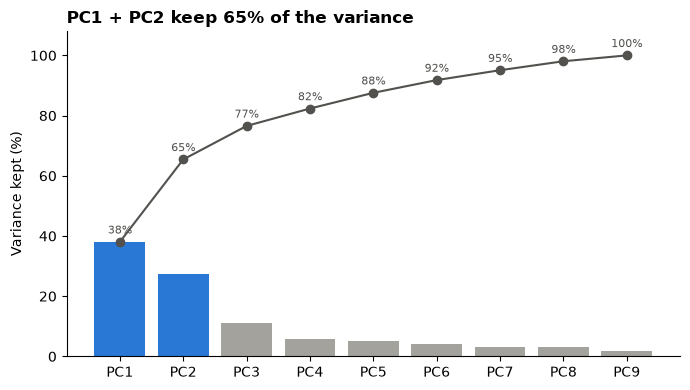

In [8]:
# Task 2.2 · Scree plot: one bar per component plus the cumulative line
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, 10)
ax.bar(x, var_pct, color=GREY)
ax.bar([1, 2], var_pct[:2], color=BLUE)
ax.plot(x, cum_pct, color=DARK, marker="o", lw=1.5)
for xi, c in zip(x, cum_pct):
    ax.annotate(f"{c:.0f}%", (xi, c), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, color=DARK)
ax.set_xticks(x)
ax.set_xticklabels([f"PC{i}" for i in x])
ax.set_ylim(0, 108)
ax.set_ylabel("Variance kept (%)")
ax.set_title(f"PC1 + PC2 keep {cum_pct[1]:.0f}% of the variance", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

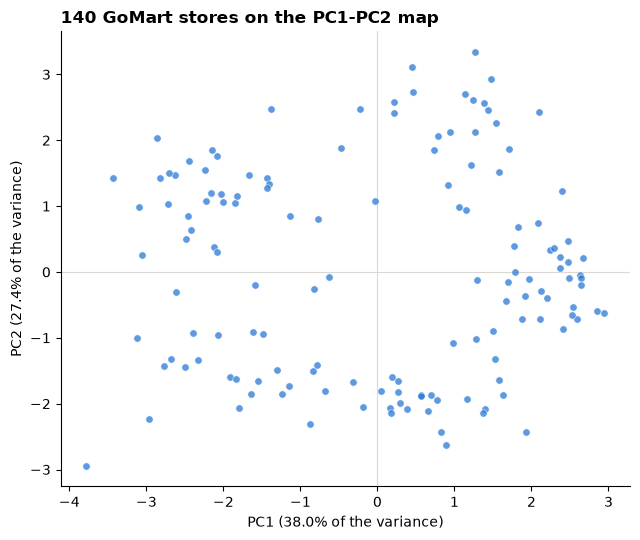

,PC1,PC2
evening_share,-0.40,0.13
median_delivery_min,-0.39,-0.17
items_per_order,-0.36,0.35
avg_basket_k,-0.18,0.49
promo_order_share,-0.17,-0.52
repeat_customer_share,0.15,0.55
orders_per_day,0.27,-0.06
ewallet_share,0.43,-0.03
ontime_share,0.47,0.13


In [9]:
# Task 2.3 · PC1-PC2 map: one dot per store, variance % in both axis labels (no clustering yet)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(scores[:, 0], scores[:, 1], s=28, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% of the variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% of the variance)")
ax.set_title("140 GoMart stores on the PC1-PC2 map", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# What drives each axis (loadings), to help read the map
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"]).round(2)
display(loadings.sort_values("PC1"))

**How much do PC1 + PC2 keep?** PC1 keeps 38.0% and PC2 keeps 27.4%, so together they keep 65.4% of the variance. About one third is spread over PC3 to PC9, so the map is a good but not a complete picture.

**What the axes mean.** PC1 is high for `ontime_share` (+0.47) and `ewallet_share` (+0.43) and low for `median_delivery_min` (-0.39) and `evening_share` (-0.40): reliable, fast, cashless stores on the right, slow evening-heavy stores on the left. PC2 is high for `repeat_customer_share` (+0.55) and `avg_basket_k` (+0.49) and low for `promo_order_share` (-0.52): loyal big-basket stores at the top, promo-driven stores at the bottom.

**Expected number of groups (written before any clustering): 4.** The dots form a loose ring with a gap in the middle, and we see four thick areas: left, bottom, right and top. The borders between neighbouring areas are blurry, so 4 is a guess to test in Task 3, not a result.

## Task 3 · Choose k

In [10]:
# Task 3.1 · Compare k = 2...8 on standardized data
# Task 3.1 · Compare k = 2...8 on standardized data
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Find the dataset from the current working directory
data_path = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "raw" / "gomart_stores_2025.csv"
    if candidate.is_file():
        data_path = candidate
        break

if data_path is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/gomart_stores_2025.csv. "
        "Hãy kiểm tra thư mục dự án."
    )

df = pd.read_csv(data_path)

features = [
    "orders_per_day",
    "avg_basket_k",
    "median_delivery_min",
    "ontime_share",
    "ewallet_share",
    "promo_order_share",
    "evening_share",
    "repeat_customer_share",
    "items_per_order"
]

X = df[features].copy()

if X.isna().any().any():
    raise ValueError(
        "Dữ liệu có giá trị thiếu. Cần kiểm tra lại Task 1."
    )

# Standardize before fitting KMeans
X_scaled = StandardScaler().fit_transform(X)
Z = X_scaled

ks = list(range(2, 9))
inertia = []
sil = []

for k in ks:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    ).fit(Z)

    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

k_results = pd.DataFrame({
    "k": ks,
    "inertia": inertia,
    "silhouette": sil
})

print(
    k_results.round({
        "inertia": 1,
        "silhouette": 3
    }).to_string(index=False)
)

 k  inertia  silhouette
 2    871.3       0.288
 3    674.0       0.295
 4    523.4       0.304
 5    420.2       0.324
 6    393.3       0.302
 7    373.8       0.260
 8    355.9       0.236


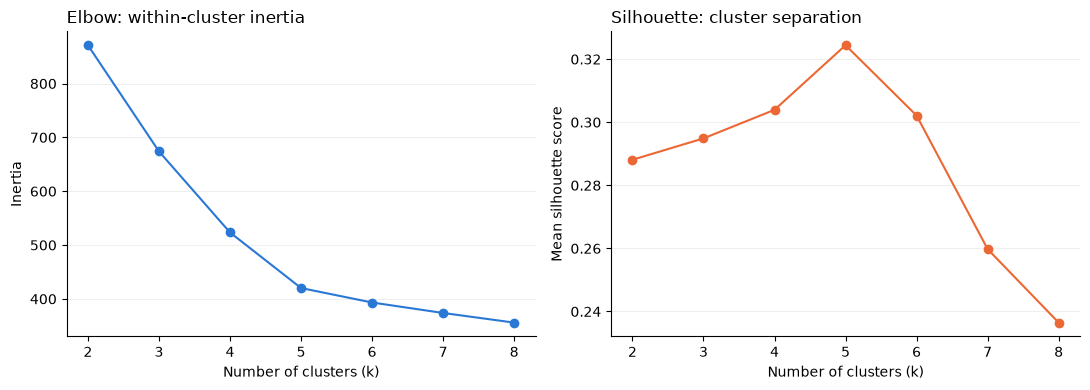

Selected number of clusters: k = 5


In [11]:
# Task 3.2 · Elbow and silhouette plots
# Task 3.2 · Elbow and silhouette plots
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
ORANGE = "#eb6834"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Elbow
axes[0].plot(
    k_results["k"],
    k_results["inertia"],
    marker="o",
    color=BLUE
)
axes[0].set_title("Elbow: within-cluster inertia", loc="left")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

# Silhouette
axes[1].plot(
    k_results["k"],
    k_results["silhouette"],
    marker="o",
    color=ORANGE
)
axes[1].set_title("Silhouette: cluster separation", loc="left")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")

for ax in axes:
    ax.set_xticks(k_results["k"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Chọn k sau khi xem xét cả elbow và silhouette
chosen_k = 5
print(f"Selected number of clusters: k = {chosen_k}")

We choose k = 5 because inertia decreases sharply from k = 2 to k = 5, then declines much more slowly for k = 6–8, suggesting an elbow around k = 5. The silhouette score also peaks at approximately 0.324 for k = 5, about 0.02 higher than for k = 4 or k = 6. Together, these plots support choosing five clusters, although the moderate silhouette score means their stability and strength relative to a shuffled baseline still need to be checked in Task 5.

## Task 4 · Cluster, profile and name

In [12]:
# Fit KMeans and deterministically map clusters to A, B, C, D, E by orders_per_day descending
from sklearn.cluster import KMeans

# 1. Fit KMeans with k = 5
km5 = KMeans(n_clusters=5, n_init=10, random_state=0)
raw_labels = km5.fit_predict(X_scaled)
df["cluster_raw"] = raw_labels

# 2. Sort clusters by mean orders_per_day descending to ensure deterministic labeling
ordered_clusters = df.groupby("cluster_raw")["orders_per_day"].mean().sort_values(ascending=False).index
letters = ["A", "B", "C", "D", "E"]
cluster_map = {orig: letter for letter, orig in zip(letters, ordered_clusters)}

# 3. Assign letter labels
df["cluster"] = df["cluster_raw"].map(cluster_map)

# 4. Display mapping and summary statistics
print("Cluster mapping (sorted by orders_per_day descending):")
for letter in letters:
    orig = [k for k, v in cluster_map.items() if v == letter][0]
    mean_ord = df[df["cluster"] == letter]["orders_per_day"].mean()
    cnt = (df["cluster"] == letter).sum()
    print(f"  Cluster {letter} (Original {orig}): {cnt} stores | Mean orders/day = {mean_ord:.1f}")

# 5. Geographic zone distribution (context only)
print("\nCluster distribution by zone:")
display(pd.crosstab(df["cluster"], df["zone"], margins=True).loc[letters + ["All"]])

Cluster mapping (sorted by orders_per_day descending):
  Cluster A (Original 1): 25 stores | Mean orders/day = 235.8
  Cluster B (Original 3): 34 stores | Mean orders/day = 232.7
  Cluster C (Original 0): 32 stores | Mean orders/day = 166.3
  Cluster D (Original 2): 23 stores | Mean orders/day = 117.8
  Cluster E (Original 4): 26 stores | Mean orders/day = 56.0

Cluster distribution by zone:


zone,Central,Inner,Outer,All
cluster,,,,
A,5,14,6,25
B,21,11,2,34
C,3,13,16,32
D,14,7,2,23
E,6,9,11,26
All,49,54,37,140


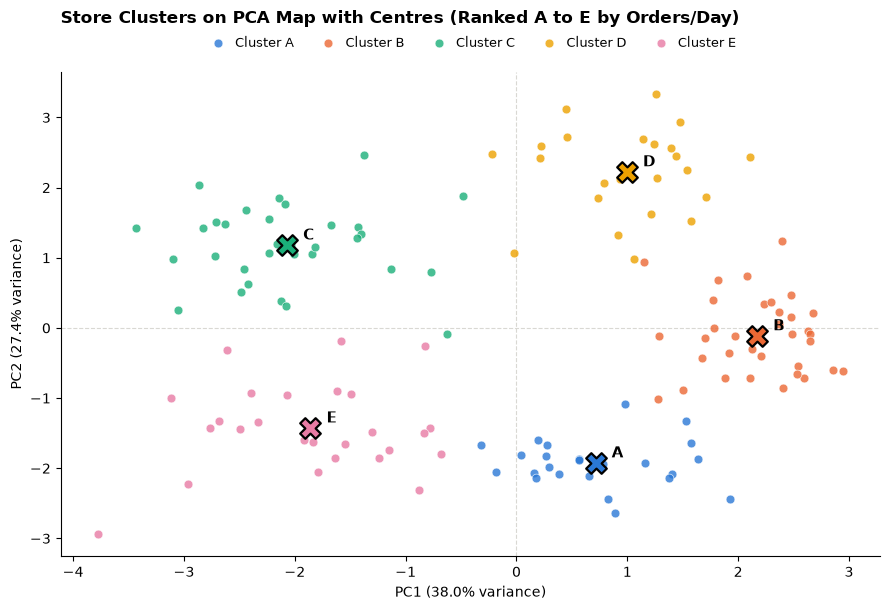

In [13]:
# Draw clusters on the PCA map with their centres (Cụm A, B, C, D, E)
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

centroids_pc = df.groupby("cluster")[["PC1", "PC2"]].mean()


CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
letters = ["A", "B", "C", "D", "E"]
cluster_labels = [f"Cluster {l}" for l in letters]

fig, ax = plt.subplots(figsize=(9, 6.2))

for idx, letter in enumerate(letters):
    subset = df[df["cluster"] == letter]
    ax.scatter(subset["PC1"], subset["PC2"],
               color=CAT[idx], label=cluster_labels[idx],
               s=40, alpha=0.8, edgecolor="white", linewidth=0.5)


for idx, letter in enumerate(letters):
    cx, cy = centroids_pc.loc[letter, "PC1"], centroids_pc.loc[letter, "PC2"]
    ax.scatter(cx, cy, color=CAT[idx], s=220, marker="X", 
               edgecolor="black", linewidth=1.6, zorder=5)
    ax.annotate(f" {letter}", (cx, cy), textcoords="offset points", xytext=(8, 4),
                fontweight="bold", fontsize=11, color="black")

ax.axhline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)
ax.axvline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)

ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% variance)")
ax.set_title("Store Clusters on PCA Map with Centres (Ranked A to E by Orders/Day)", 
             loc="left", fontweight="bold", fontsize=12, pad=35)

ax.legend(bbox_to_anchor=(0.5, 1.02), loc="lower center", ncol=5,
          frameon=False, fontsize=9.5, handletextpad=0.3, columnspacing=1.6)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

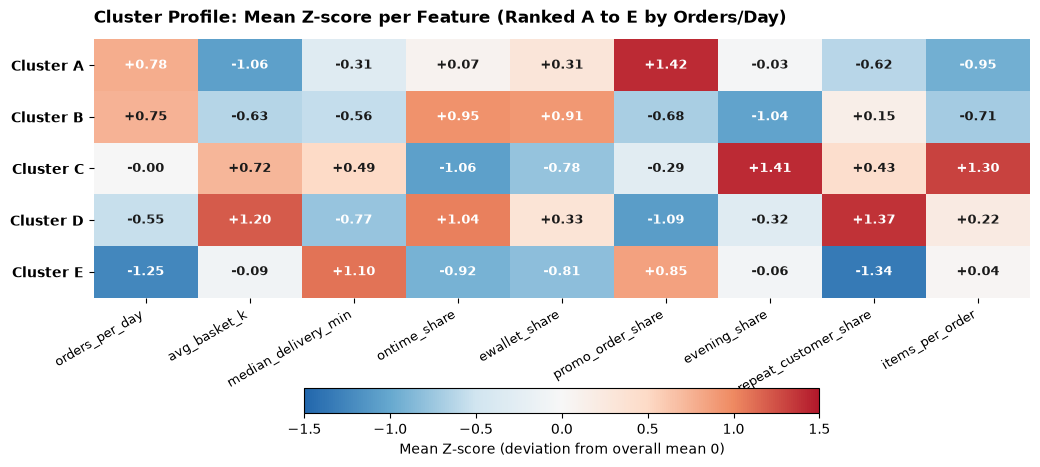

In [14]:
# Profile heatmap: Colorblind-safe Blue-White-Red diverging palette (Cluster A to E)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

letters = ["A", "B", "C", "D", "E"]
profile_z = pd.DataFrame(X_scaled, columns=features).groupby(df["cluster"]).mean().loc[letters]

safe_colors = ["#2166ac", "#67a9cf", "#d1e5f0", "#f7f7f7", "#fddbc7", "#ef8a62", "#b2182b"]
safe_cmap = LinearSegmentedColormap.from_list("safe_rdbu", safe_colors)

norm = TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
cax = ax.imshow(profile_z.values, cmap=safe_cmap, norm=norm, aspect="auto")

for i in range(profile_z.shape[0]):
    for j in range(profile_z.shape[1]):
        val = profile_z.iloc[i, j]

        text_color = "white" if abs(val) >= 0.75 else "#1a1a1a"
        ax.text(j, i, f"{val:+.2f}", ha="center", va="center",
                color=text_color, fontsize=9.5, fontweight="bold")

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=30, ha="right", fontsize=9.5)
ax.set_yticks(range(5))
ax.set_yticklabels([f"Cluster {ltr}" for ltr in letters], fontsize=10, fontweight="bold")
ax.set_title("Cluster Profile: Mean Z-score per Feature (Ranked A to E by Orders/Day)", 
             loc="left", fontweight="bold", fontsize=12, pad=12)

cbar = fig.colorbar(cax, ax=ax, orientation="horizontal", pad=0.22, shrink=0.55)
cbar.set_label("Mean Z-score (deviation from overall mean 0)")

ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

**Names.** For each cluster, a behaviour name and the two or three profile cells that justify it:

| cluster | name | justified by (profile cells) |
|:---:|---|---|
| **A** | **High-volume discount small basket stores** | `orders_per_day` (+0.78z / 235.8), `promo_order_share` (+1.42z / 56.8%), `avg_basket_k` (-1.06z / 115.6k). Highest daily order volume across the network, driven heavily by promotional discounts, resulting in the smallest basket values and low item counts per order. |
| **B** | **Daytime digital grab-and-go stores** | `evening_share` (-1.04z / 20.9%), `ewallet_share` (+0.91z / 68.7%), `ontime_share` (+0.95z / 87.3%), `median_delivery_min` (-0.56z / 24.3 mins). Orders take place almost entirely during daytime hours with dominant e-wallet adoption, characterized by rapid fulfillment and reliable on-time delivery. |
| **C** | **Evening large-basket grocery stores** | `evening_share` (+1.41z / 63.5%), `items_per_order` (+1.30z / 12.3 items), `ontime_share` (-1.06z / 54.3%). Concentrated evening shopping with large household item counts per basket, causing operational bottlenecks and the lowest on-time delivery rates. |
| **D** | **Loyal premium fast-delivery stores** | `repeat_customer_share` (+1.37z / 76.0%), `avg_basket_k` (+1.20z / 385.3k), `median_delivery_min` (-0.77z / 21.6 mins). Highest basket value powered by loyal returning customers with negligible promotional dependence (-1.09z), supported by fast delivery and exceptional punctuality (88.8%). |
| **E** | **Slow-delivery low-traffic promo stores** | `orders_per_day` (-1.25z / 56.0), `median_delivery_min` (+1.10z / 45.0 mins), `repeat_customer_share` (-1.34z / 29.3%). Lowest foot-traffic/order volume and slowest delivery times in the network, experiencing severe customer churn despite moderate promotional reliance (+0.85z). |

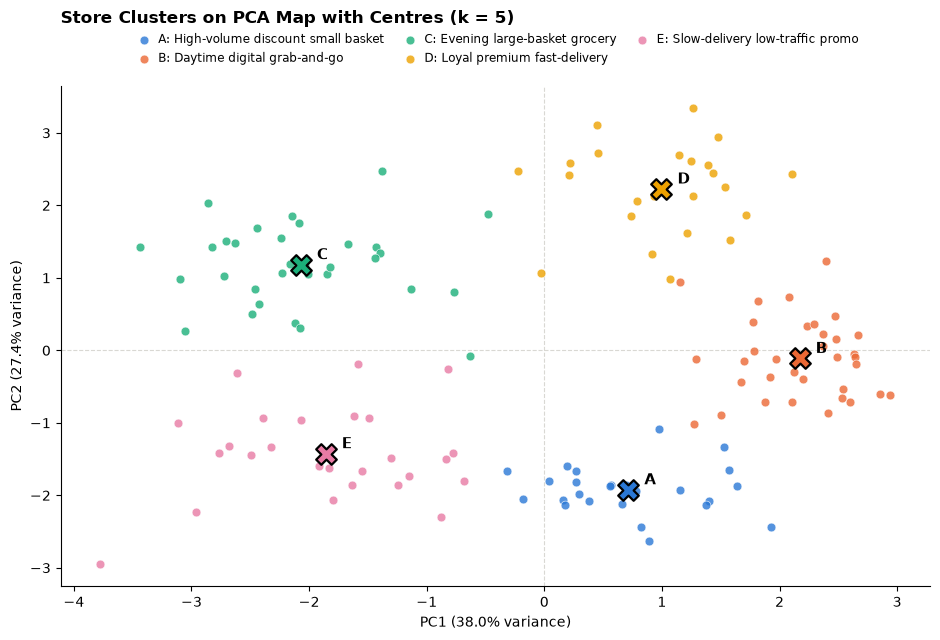

In [15]:
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

centroids_pc = df.groupby("cluster")[["PC1", "PC2"]].mean()

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
letters = ["A", "B", "C", "D", "E"]
cluster_names = [
    "A: High-volume discount small basket",
    "B: Daytime digital grab-and-go",
    "C: Evening large-basket grocery",
    "D: Loyal premium fast-delivery",
    "E: Slow-delivery low-traffic promo"
]

fig, ax = plt.subplots(figsize=(9.5, 6.5))


for idx, letter in enumerate(letters):
    subset = df[df["cluster"] == letter]
    ax.scatter(subset["PC1"], subset["PC2"],
               color=CAT[idx], label=cluster_names[idx],
               s=40, alpha=0.8, edgecolor="white", linewidth=0.5)

for idx, letter in enumerate(letters):
    cx, cy = centroids_pc.loc[letter, "PC1"], centroids_pc.loc[letter, "PC2"]
    ax.scatter(cx, cy, color=CAT[idx], s=220, marker="X", 
               edgecolor="black", linewidth=1.6, zorder=5)
    ax.annotate(f" {letter}", (cx, cy), textcoords="offset points", xytext=(8, 4),
                fontweight="bold", fontsize=11, color="black")


ax.axhline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)
ax.axvline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)

ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% variance)")
ax.set_title("Store Clusters on PCA Map with Centres (k = 5)", 
             loc="left", fontweight="bold", fontsize=12, pad=45)

ax.legend(bbox_to_anchor=(0.5, 1.02), loc="lower center", ncol=3,
          frameon=False, fontsize=8.5, handletextpad=0.2, columnspacing=1.2)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Task 5 · Are the groups real?
### 5.1 Different seeds and a different method (Ward)

In [16]:
# Task 5.1 · Check stability across different random seeds
K = 5
Z = X_scaled

# 1. Run KMeans with 3 different random seeds
seeds = [0, 1, 2]
labs = [KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z).labels_ for s in seeds]

print("=== 5.1 Stability Across Different Seeds ===")
print(f"ARI (seed 0 vs 1): {adjusted_rand_score(labs[0], labs[1]):.3f}")
print(f"ARI (seed 0 vs 2): {adjusted_rand_score(labs[0], labs[2]):.3f}")
print(f"ARI (seed 1 vs 2): {adjusted_rand_score(labs[1], labs[2]):.3f}")



=== 5.1 Stability Across Different Seeds ===
ARI (seed 0 vs 1): 1.000
ARI (seed 0 vs 2): 1.000
ARI (seed 1 vs 2): 1.000


In [17]:
# Compare with Ward hierarchical clustering
from scipy.cluster.hierarchy import linkage, fcluster

print("\n=== 5.2 Comparison with Ward Hierarchical Clustering ===")
L = linkage(Z, method="ward")
ward = fcluster(L, K, criterion="maxclust")
df["ward"] = ward

# Cross-tabulation between K-Means (A-E) and Ward (1-5)
letters = ["A", "B", "C", "D", "E"]
ct = pd.crosstab(df["cluster"], df["ward"], rownames=["k-means"], colnames=["Ward"]).loc[letters]
print("Cross-tabulation (k-means vs Ward):")
display(ct)

ari_ward = adjusted_rand_score(df["cluster"], ward)
print(f"Adjusted Rand Index (k-means vs Ward): {ari_ward:.3f}")

# Identify stores classified differently
# 'home' maps each k-means cluster to its dominant Ward group
home = ct.idxmax(axis=1)
print("\nDominant Ward group for each k-means cluster:")
for ltr, h in home.items():
    print(f"  Cluster {ltr} -> Ward {h}")

moved_mask = df["ward"] != df["cluster"].map(home).values
moved = df.loc[moved_mask, ["store_id", "cluster", "ward", "zone"]]

print(f"\nStores classified differently ({len(moved)}/140 stores, {len(moved)/len(df)*100:.1f}%):")
display(moved)


=== 5.2 Comparison with Ward Hierarchical Clustering ===
Cross-tabulation (k-means vs Ward):


Ward,1,2,3,4,5
k-means,,,,,
A,0,0,0,25,0
B,0,0,1,0,33
C,30,2,0,0,0
D,1,0,22,0,0
E,0,26,0,0,0


Adjusted Rand Index (k-means vs Ward): 0.929

Dominant Ward group for each k-means cluster:
  Cluster A -> Ward 4
  Cluster B -> Ward 5
  Cluster C -> Ward 1
  Cluster D -> Ward 3
  Cluster E -> Ward 2

Stores classified differently (4/140 stores, 2.9%):


,store_id,cluster,ward,zone
18,S019,D,1,Outer
56,S057,C,2,Outer
61,S062,C,2,Outer
78,S079,B,3,Inner


### 5.2 A null baseline (shuffle each column)

In [18]:
# Task 5.2 · Null baseline by independently shuffling each feature

# Silhouette score of the real clustering
real_silhouette = silhouette_score(Z, df["cluster_raw"])

print(f"Real silhouette score: {real_silhouette:.3f}")

Real silhouette score: 0.324


In [21]:
# Create null datasets by independently shuffling each feature

rng = np.random.default_rng(42)
n_repeats = 20
null_silhouettes = []

for i in range(n_repeats):
    # Make a copy of the standardized data
    Z_null = Z.copy()

    # Shuffle each feature independently
    for j in range(Z_null.shape[1]):
        Z_null[:, j] = rng.permutation(Z_null[:, j])

    # Run KMeans with the same k = 5
    km_null = KMeans(n_clusters=K, n_init=10, random_state=i)
    null_labels = km_null.fit_predict(Z_null)

    # Calculate silhouette score
    null_score = silhouette_score(Z_null, null_labels)
    null_silhouettes.append(null_score)

null_silhouettes = np.array(null_silhouettes)

print(f"Real silhouette: {real_silhouette:.3f}")
print(f"Null mean: {null_silhouettes.mean():.3f}")
print(f"Null range: {null_silhouettes.min():.3f} to {null_silhouettes.max():.3f}")
print(f"Null runs >= real: {(null_silhouettes >= real_silhouette).sum()}/{n_repeats}")

Real silhouette: 0.324
Null mean: 0.105
Null range: 0.088 to 0.125
Null runs >= real: 0/20


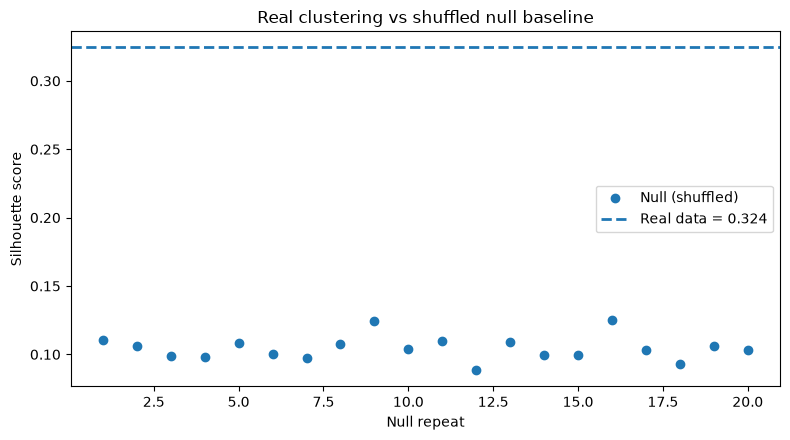

In [22]:
# Visual comparison: real silhouette vs null baseline

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.scatter(
    range(1, n_repeats + 1),
    null_silhouettes,
    label="Null (shuffled)"
)

ax.axhline(
    real_silhouette,
    linestyle="--",
    linewidth=2,
    label=f"Real data = {real_silhouette:.3f}"
)

ax.set_xlabel("Null repeat")
ax.set_ylabel("Silhouette score")
ax.set_title("Real clustering vs shuffled null baseline")
ax.legend()

plt.tight_layout()
plt.show()

**Null baseline interpretation.**  
The real clustering achieved a silhouette score of **0.324**, while the 20 independently shuffled null datasets had a mean silhouette of **0.105**, ranging from **0.088 to 0.125**. None of the 20 null runs achieved a silhouette score equal to or higher than the real data (**0/20**). This suggests that the cluster structure in the real data is meaningfully stronger than what would be expected after destroying the relationships among features.

In [23]:
# Inspect standardized profiles of stores where KMeans and Ward disagree

moved_ids = moved["store_id"].tolist()

moved_profiles = pd.DataFrame(
    Z,
    columns=features,
    index=df["store_id"]
)

display(moved_profiles.loc[moved_ids].round(2))

,orders_per_day,avg_basket_k,median_delivery_min,ontime_share,ewallet_share,promo_order_share,evening_share,repeat_customer_share,items_per_order
store_id,,,,,,,,,
S019,-0.39,0.22,-0.42,-0.41,0.26,-0.57,0.69,1.08,-0.15
S057,-0.79,0.59,1.60,-0.72,-0.67,-0.36,1.26,-0.14,0.13
S062,-0.29,1.63,1.73,-0.17,-1.00,-0.36,0.69,0.03,0.69
S079,0.38,0.17,1.13,1.11,0.86,-1.38,-0.63,0.67,-0.15


**Stores where K-Means and Ward disagree.**  
Only 4 of 140 stores (2.9%) were assigned differently by the two methods. These stores show mixed feature profiles rather than clearly matching a single cluster. S019 combines high repeat-customer and evening shares; S057 combines high evening activity with low order volume and slow delivery; S062 has a large basket and high evening share but very slow delivery and low e-wallet usage; and S079 combines high on-time and e-wallet shares with very low promotion usage. These mixed characteristics suggest that the four stores are relatively ambiguous or boundary cases, which helps explain why K-Means and Ward classify them differently.

*Verdict: are the groups stable and above the null? If a method disagrees, which stores move and why?*

### Final verdict

The five-cluster solution appears stable and meaningfully stronger than the null baseline. K-Means produced identical assignments across three random seeds (ARI = 1.000), showing strong stability to initialization. Ward hierarchical clustering also agreed closely with K-Means (ARI = 0.929), with only 4 of 140 stores (2.9%) classified differently. These stores have mixed feature profiles, suggesting that they are relatively ambiguous cases between groups. Finally, the real silhouette score (0.324) was substantially higher than the shuffled null baseline (mean = 0.105, range = 0.088–0.125), and none of the 20 null runs matched or exceeded the real score (0/20). Overall, the evidence supports a stable and meaningful cluster structure, although the moderate silhouette score indicates that the groups are not perfectly separated.

## Task 6 · The one-page chart
*Three panels or one; one action title; consistent colours. Copy the final chart to the memo at the top.*

In [19]:
# TODO: write your code here

## Task 7 · Team and AI
| Member | What they did | Share of work |
|---|---|---|
| | | |

In [20]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves (every k, name and claim):
"""
print(AI_USE)


Tool(s) used:
What we asked:
What we checked or changed ourselves (every k, name and claim):

